# FAANG+M Narrative-to-Numbers Research Desk

## An Auditable Multi-Agent Financial Analysis System

**Companies:** Meta, Apple, Amazon, Netflix, Alphabet, and Microsoft  
**As-of date:** September 7, 2026  
**Course:** AAI-520 Natural Language Processing  
**Deliverable:** Final Team Project

This notebook investigates whether each company's AI and growth narrative is supported by reported financial execution, filing disclosures, recent news, and market behavior. It demonstrates autonomous planning, dynamic tool selection, prompt chaining, routing, evaluator-optimizer reflection, and validated memory across runs.

> **Responsible-use statement:** This is educational research, not investment advice. Results are descriptive, source-dependent, and do not predict future returns.

## 1. Executive Summary and Rubric Map

The project uses a **primary-source-first** evidence hierarchy: SEC EDGAR filings and XBRL facts, Yahoo Finance price/news metadata, deterministic analytics, then model-assisted synthesis. A material claim is accepted only when its evidence ID exists in the registry.

The autonomous agent visibly **plans research steps**, **uses tools dynamically**, performs **self-reflection**, and **learns across runs** through validated persistent memory.

| Requirement | Implementation evidence in this notebook |
| --- | --- |
| Plans research steps | Query-specific plan and single-symbol planner probe |
| Uses tools dynamically | Full comparison and regulatory-news-only plans select different tools |
| Self-reflects | Version 0 report is evaluated, revised, and rescored |
| Learns across runs | Cold/warm comparison shows validated memory reuse and fewer fallbacks |
| Prompt chaining | Ingest News → Preprocess → Classify → Extract → Summarize |
| Routing | Filing, news, market, macro, and mixed specialist routes |
| Evaluator-optimizer | Generate → evaluate → revise → accept bounded loop |
| Code quality | Installable package, tests, Ruff checks, citations, charts, and integrity assertions |

**Research question:** Which FAANG+M companies show the largest gaps between AI narrative, capital commitment, cash-flow support, independent news, and observed market reaction?

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import faangm_research
from faangm_research.agents.memory import ResearchMemory
from faangm_research.agents.planner import build_research_plan
from faangm_research.analytics.financials import financial_panel, latest_company_metrics
from faangm_research.analytics.market import market_summary
from faangm_research.config import COMPANIES, Settings
from faangm_research.evaluation import memory_comparison, report_claim_audit
from faangm_research.graph import run_research
from faangm_research.schemas import PlanStep
from faangm_research.snapshot import load_snapshot

ROOT = next(path for path in (Path.cwd(), Path.cwd().parent) if (path / "pyproject.toml").exists())
SETTINGS = Settings.default(root=ROOT, offline=True)
np.random.seed(SETTINGS.seed)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Package:", faangm_research.__version__, Path(faangm_research.__file__).resolve())
print("Pandas:", metadata.version("pandas"), "| LangGraph:", metadata.version("langgraph"))
print("Seed:", SETTINGS.seed, "| Offline frozen mode:", SETTINGS.offline)

Python: 3.12.14
Platform: macOS-26.6.2-arm64-arm-64bit
Package: 0.1.0 /Users/vikrant/Projects/USD/AAI-520-NLP/Final_Project/src/faangm_research/__init__.py
Pandas: 2.3.3 | LangGraph: 1.2.11
Seed: 520 | Offline frozen mode: True


## 2. System Architecture, Agent Design, and Data Sources

The implementation separates reliable calculations from model-driven decisions. LangGraph owns state and conditional control flow; Pydantic rejects malformed plans and claims; SEC and Yahoo source adapters cache every response with provenance.

```text
User query → Supervisor plan → Dynamic tools → Evidence registry
                ↓                          ↓
          specialist router → Filing / News / Market / Macro
                ↓
          evidence synthesis → evaluator
                ↑                 ↓
                └── revision feedback (maximum two revisions)
                                  ↓
                          accepted memory update
```

The notebook executes exactly two end-to-end runs over identical frozen data: a cold-memory run and a warm-memory rerun. Lightweight planner probes demonstrate that the same agent also handles a single stock symbol and narrow requests.

In [2]:
facts, source_evidence, prices = load_snapshot(ROOT / "data" / "processed")
manifest = json.loads((ROOT / "data" / "manifest.json").read_text(encoding="utf-8"))

coverage = (
    pd.DataFrame([item.model_dump(mode="json") for item in source_evidence])
    .groupby(["ticker", "document_type"])
    .size()
    .unstack(fill_value=0)
)
fact_coverage = (
    pd.DataFrame([item.model_dump(mode="json") for item in facts])
    .groupby(["ticker", "metric"])
    .size()
    .unstack(fill_value=0)
)

print(f"Frozen snapshot: {len(facts)} financial facts, {len(source_evidence)} source documents, {len(prices)} price rows")
print(f"Manifest entries: {manifest['file_count']} | Price window: {prices.index.min().date()} to {prices.index.max().date()}")
display(coverage)
display(fact_coverage)

Frozen snapshot: 105 financial facts, 48 source documents, 255 price rows
Manifest entries: 34 | Price window: 2025-09-02 to 2026-09-04


document_type,10-K,10-Q,news
ticker,,,
AAPL,1,1,6
AMZN,1,1,6
GOOGL,1,1,6
META,1,1,6
MSFT,1,1,6
NFLX,1,1,6


metric,capital_expenditures,net_income,operating_cash_flow,operating_income,research_and_development,revenue
ticker,,,,,,
AAPL,3,3,3,3,3,3
AMZN,3,3,3,3,0,3
GOOGL,3,3,3,3,3,3
META,3,3,3,3,3,3
MSFT,3,3,3,3,3,3
NFLX,3,3,3,3,3,3


## 3. Financial Execution: Narrative Capacity in Numbers

The comparison uses reported annual SEC facts and preserves each fiscal year, filing accession, and XBRL concept. Free cash flow is an analytical measure defined here as:

$$\text{FCF}=\text{Operating Cash Flow}-\text{Capital Expenditures}$$

$$\text{FCF Margin}=\frac{\text{FCF}}{\text{Revenue}},\qquad \text{Capex Intensity}=\frac{\text{Capital Expenditures}}{\text{Revenue}}$$

Amazon reports recent productive-asset purchases under `PaymentsToAcquireProductiveAssets`; the concept is retained and disclosed rather than silently relabeled. Amazon lacks the standard `ResearchAndDevelopmentExpense` tag, so its R&D comparison remains missing instead of using a false equivalent.

metric,ticker,fiscal_year,revenue_growth,operating_margin,fcf_margin,capex_intensity,rd_intensity
0,AAPL,2025,-2.8%,29.8%,26.0%,2.9%,7.8%
1,AMZN,2025,11.8%,6.4%,5.6%,9.2%,Not comparable
2,GOOGL,2025,8.7%,27.4%,22.6%,10.5%,14.8%
3,META,2025,15.7%,34.7%,32.7%,20.0%,28.5%
4,MSFT,2026,15.7%,44.6%,30.2%,18.1%,12.0%
5,NFLX,2025,6.7%,20.6%,20.5%,1.0%,7.9%


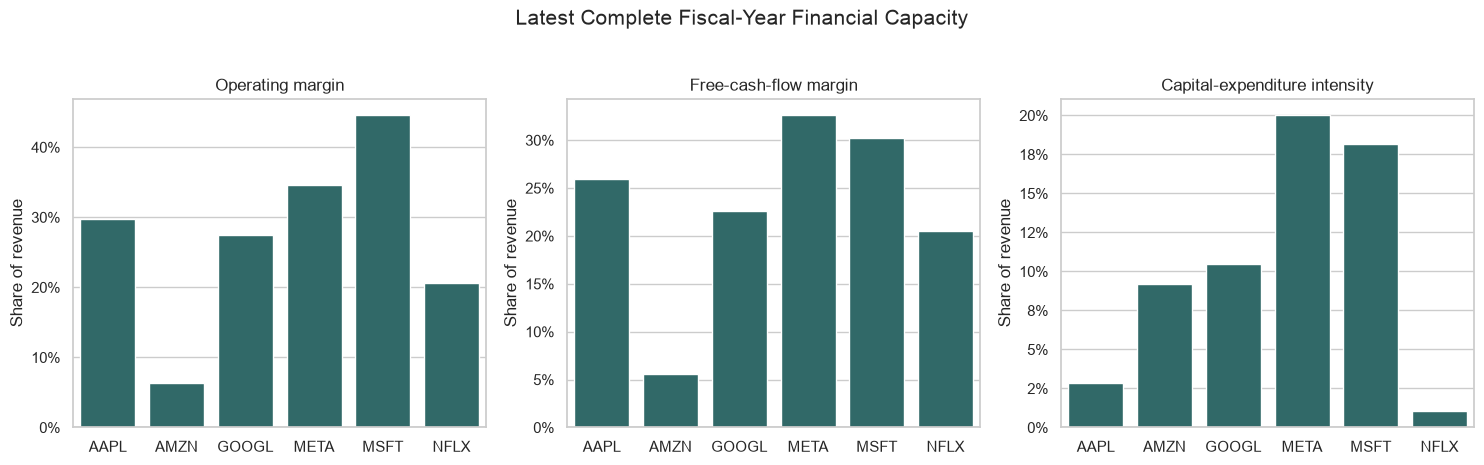

In [3]:
panel = financial_panel(facts)
latest = latest_company_metrics(panel)
percent_columns = ["revenue_growth", "operating_margin", "fcf_margin", "capex_intensity", "rd_intensity"]
latest_display = latest[["ticker", "fiscal_year", *percent_columns]].copy()
for column in percent_columns:
    latest_display[column] = latest_display[column].map(lambda value: f"{value:.1%}" if pd.notna(value) else "Not comparable")

display(latest_display)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, metric, title in zip(
    axes,
    ["operating_margin", "fcf_margin", "capex_intensity"],
    ["Operating margin", "Free-cash-flow margin", "Capital-expenditure intensity"],
):
    sns.barplot(data=latest, x="ticker", y=metric, ax=axis, color="#287271")
    axis.axhline(0, color="#20262e", linewidth=0.8)
    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel("Share of revenue")
    axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.suptitle("Latest Complete Fiscal-Year Financial Capacity", fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

,ticker,observations,total_return,annualized_volatility,max_drawdown,benchmark_excess_return
0,AAPL,255,39.8%,25.2%,-13.8%,12.1%
1,AMZN,255,14.7%,34.5%,-21.7%,-13.0%
2,GOOGL,255,60.7%,32.6%,-21.0%,33.0%
3,META,255,-15.8%,38.8%,-32.5%,-43.5%
4,MSFT,255,-0.3%,32.4%,-34.5%,-28.0%
5,NFLX,255,-35.5%,35.8%,-46.5%,-63.3%
6,QQQ,255,27.7%,19.5%,-12.0%,0.0%


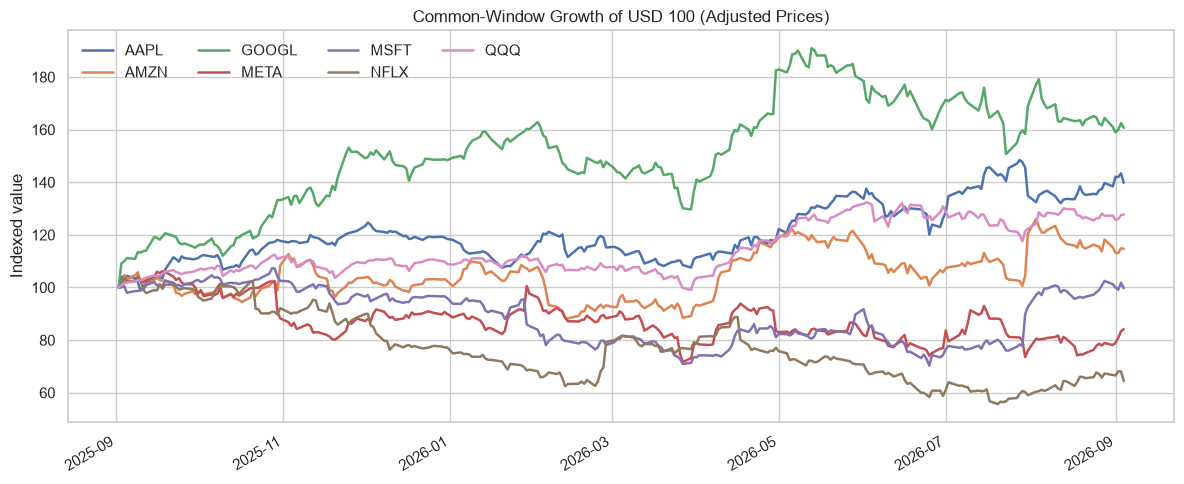

In [4]:
market = market_summary(prices, benchmark=SETTINGS.benchmark)
market_display = market.copy()
for column in ["total_return", "annualized_volatility", "max_drawdown", "benchmark_excess_return"]:
    market_display[column] = market_display[column].map(lambda value: f"{value:.1%}")
display(market_display)

normalized = prices.div(prices.iloc[0]).mul(100)
fig, axis = plt.subplots(figsize=(12, 5))
normalized.plot(ax=axis, linewidth=1.8)
axis.set_title("Common-Window Growth of USD 100 (Adjusted Prices)")
axis.set_ylabel("Indexed value")
axis.set_xlabel("")
axis.legend(ncol=4, frameon=False)
plt.tight_layout()
plt.show()

## 4. Local NLP Models and Resource Controls

Models are loaded sequentially rather than simultaneously:

1. **ProsusAI/FinBERT** classifies financial sentiment as positive, negative, or neutral.
2. **all-MiniLM-L6-v2** embeds filing chunks for semantic retrieval.
3. **Qwen2.5-1.5B-Instruct** proposes structured research plans and receives one JSON repair opportunity.

Every Qwen plan is parsed into the strict `PlanStep` schema. If both generation and repair fail, the agent records the failure and uses its deterministic query-aware plan. This is a visible fallback, not silent replacement.

In [5]:
model_dir = ROOT / "outputs" / "model"
model_measurements_path = model_dir / "model_measurements.csv"
qwen_benchmark_path = model_dir / "qwen_benchmark.json"
finbert_path = model_dir / "finbert_sentiment.csv"

assert model_measurements_path.exists(), "Run scripts/benchmark_models.py before executing the notebook"
model_measurements = pd.read_csv(model_measurements_path)
qwen_cases = pd.DataFrame(json.loads(qwen_benchmark_path.read_text(encoding="utf-8")))
finbert_results = pd.read_csv(finbert_path)

display(model_measurements)
print(f"Qwen schema-valid rate: {qwen_cases['schema_valid'].mean():.1%}")
print(f"Qwen repair rate: {qwen_cases['repair_used'].mean():.1%}")
print(f"Qwen deterministic-fallback rate: {qwen_cases['fallback_used'].mean():.1%}")
display(finbert_results[["ticker", "title", "label", "positive", "negative", "neutral"]].head(8))

,model,device,load_seconds,inference_seconds,rss_before_mb,rss_after_mb,records
0,ProsusAI/finbert,mps,29.605981,0.739295,253.296875,322.18750,12
1,Qwen/Qwen2.5-1.5B-Instruct,mps,131.156819,273.581659,483.625000,365.53125,12


Qwen schema-valid rate: 91.7%
Qwen repair rate: 0.0%
Qwen deterministic-fallback rate: 8.3%


,ticker,title,label,positive,negative,neutral
0,META,"Palantir Stock Leads August Rally -- Nvidia, Salesforce and Super Micro Jump",positive,0.786015,0.166851,0.047133
1,META,"How a 64-Year-Old’s $1.2 Million in VOO Turned Into a $456,000 Bet on a Single Sector",neutral,0.042179,0.038932,0.918889
2,META,Jim Cramer Says Meta (META) is “At the Price” After Settlement Eases Major Legal Overhang,negative,0.031589,0.486344,0.482067
3,META,"Nvidia, Microsoft at Center of $7 Trillion AI Boom",positive,0.587493,0.046638,0.365869
4,META,AMD Is Behind The AI Chip Shift Nobody Is Talking About,neutral,0.383358,0.040635,0.576007
5,META,Alphabet May Be the Mag 7 Stock Investors Are Underestimating,neutral,0.069566,0.122146,0.808288
6,AAPL,"Palantir Stock Leads August Rally -- Nvidia, Salesforce and Super Micro Jump",positive,0.786015,0.166851,0.047133
7,AAPL,Apple's $54 Billion iPhone Engine Hits an AI Memory Squeeze,negative,0.045926,0.920133,0.033942


## 5. Filing Retrieval Evaluation

The filing corpus contains section-traceable 900-character chunks with 120-character overlap. Twelve fixed cross-company questions test whether the correct company's filing appears in the top results. The lexical TF-IDF baseline is compared with MiniLM under the same questions and corpus.

$$\operatorname{Recall@k}=\frac{\text{questions with a correct-company chunk in top }k}{\text{questions evaluated}}$$

Ticker-level recall is a conservative traceability test for this comparative corpus; it does not prove that every returned sentence fully answers the question.

,method,chunks,build_seconds,recall_at_1,recall_at_3,recall_at_5,mrr,mean_latency_seconds
0,tfidf,4484.0,0.288441,0.416667,0.833333,0.916667,0.627778,0.006078
1,minilm,4484.0,45.716200,0.916667,1.000000,1.000000,0.944444,0.015120


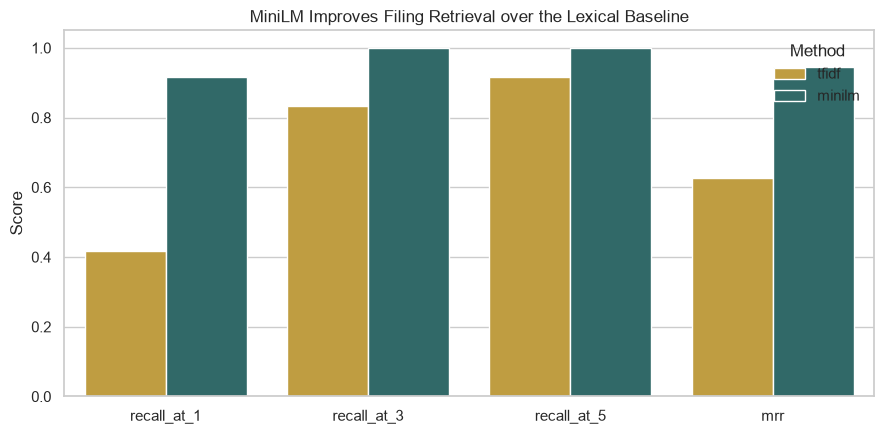

Selected retriever: minilm | Recall@3: 100.0% | MRR: 0.944


In [6]:
retrieval_metrics = pd.concat(
    [
        pd.read_csv(ROOT / "outputs" / "tables" / "retrieval_tfidf_metrics.csv"),
        pd.read_csv(ROOT / "outputs" / "tables" / "retrieval_minilm_metrics.csv"),
    ],
    ignore_index=True,
)
display(retrieval_metrics)

plot_data = retrieval_metrics.melt(
    id_vars="method",
    value_vars=["recall_at_1", "recall_at_3", "recall_at_5", "mrr"],
    var_name="metric",
    value_name="score",
)
fig, axis = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_data, x="metric", y="score", hue="method", ax=axis, palette=["#d4a72c", "#287271"])
axis.set_ylim(0, 1.05)
axis.set_title("MiniLM Improves Filing Retrieval over the Lexical Baseline")
axis.set_xlabel("")
axis.set_ylabel("Score")
axis.legend(title="Method", frameon=False)
plt.tight_layout()
plt.show()

selected_retriever = retrieval_metrics.sort_values(["recall_at_3", "mrr"], ascending=False).iloc[0]
print(f"Selected retriever: {selected_retriever['method']} | Recall@3: {selected_retriever['recall_at_3']:.1%} | MRR: {selected_retriever['mrr']:.3f}")

## 6. Autonomous Planning and Dynamic Tool Use

The supervisor plans before acting. Qwen proposes the full comparative plan; strict schema validation and a final-step invariant determine whether it is accepted. The lightweight probes below use the same query-aware planning contract to prove that the agent can narrow its work for one symbol or one risk domain.

A plan is evidence, not hidden chain-of-thought: the notebook displays operational objectives, selected tools, dependencies, success criteria, and fallbacks without exposing private reasoning traces.

In [7]:
validated_plan = [
    PlanStep.model_validate(item)
    for item in json.loads((model_dir / "validated_qwen_plan.json").read_text(encoding="utf-8"))
]
msft_probe = build_research_plan("Assess Microsoft's AI investment narrative and financial capacity")
regulatory_probe = build_research_plan("Compare META and GOOGL regulatory-news risk only")

def plan_table(plan, label):
    return pd.DataFrame(
        [
            {
                "plan": label,
                "step": step.step_id,
                "agent": step.agent,
                "objective": step.objective,
                "selected_tool": step.selected_tool,
                "dependencies": ", ".join(step.dependencies) or "None",
            }
            for step in plan
        ]
    )

plans = pd.concat(
    [plan_table(validated_plan, "Qwen FAANG+M"), plan_table(msft_probe, "MSFT probe"), plan_table(regulatory_probe, "Regulatory probe")],
    ignore_index=True,
)
display(plans)

regulatory_tools = set(plans.loc[plans["plan"] == "Regulatory probe", "selected_tool"])
assert "fred" not in regulatory_tools and "market_analytics" not in regulatory_tools
print("Dynamic routing check passed: the regulatory-only probe omitted market and macro tools.")

,plan,step,agent,objective,selected_tool,dependencies
0,Qwen FAANG+M,P1,filing_specialist,Collect and normalize primary-source financial evidence,sec_companyfacts,None
1,Qwen FAANG+M,P2,news_specialist,Run the five-stage news chain,news_chain,P1
2,Qwen FAANG+M,P3,market_specialist,"Measure risk, return, and benchmark-relative confirmation",market_analytics,P1
3,Qwen FAANG+M,P4,narrative_specialist,Compare FAANG+M AI narrative,narrative_comparison,P1
4,Qwen FAANG+M,P5,supervisor,"Synthesize, evaluate, and revise the evidence-linked report",evaluator_optimizer,"P1, P2, P3, P4"
5,MSFT probe,P1,filing_specialist,Collect and normalize primary-source financial evidence,sec_companyfacts,None
6,MSFT probe,P2,news_specialist,Run the five-stage news chain,news_chain,P1
7,MSFT probe,P5,supervisor,"Synthesize, evaluate, and revise the evidence-linked report",evaluator_optimizer,"P1, P2"
8,Regulatory probe,P1,filing_specialist,Collect and normalize primary-source financial evidence,sec_companyfacts,None
9,Regulatory probe,P2,news_specialist,Run the five-stage news chain,news_chain,P1


Dynamic routing check passed: the regulatory-only probe omitted market and macro tools.


In [8]:
QUERY = (
    "Compare FAANG+M and identify the largest gaps between AI narrative, capital "
    "commitment, cash-flow support, news sentiment, and market reaction."
)
sentiment_overrides = dict(
    zip(finbert_results["evidence_id"], finbert_results["label"], strict=True)
)
notebook_memory_path = ROOT / "outputs" / "memory" / "notebook_agent_memory.sqlite"
notebook_memory = ResearchMemory(notebook_memory_path)
notebook_memory.reset()

cold_state = run_research(
    QUERY,
    facts,
    prices,
    source_evidence,
    SETTINGS,
    notebook_memory,
    run_label="notebook-cold",
    plan_override=validated_plan,
    sentiment_overrides=sentiment_overrides,
)
warm_state = run_research(
    QUERY,
    facts,
    prices,
    source_evidence,
    SETTINGS,
    notebook_memory,
    run_label="notebook-warm",
    plan_override=validated_plan,
    sentiment_overrides=sentiment_overrides,
)
notebook_memory.close()

run_comparison = memory_comparison(cold_state, warm_state)
display(run_comparison)
print("Cold path:", " → ".join(item.decision for item in cold_state["evaluations"]))
print("Warm path:", " → ".join(item.decision for item in warm_state["evaluations"]))

,run,memory_records_used,fallback_lookups,revisions,quality_score,accepted
0,cold,0,3,1,100.0,True
1,warm,36,0,1,100.0,True


Cold path: revise → accept
Warm path: revise → accept


In [9]:
tool_trace = pd.DataFrame(
    [
        {
            "tool": event.tool,
            "success": event.success,
            "records": event.record_count,
            "cache_hit": event.cache_hit,
            "elapsed_ms": (event.ended_at - event.started_at).total_seconds() * 1000,
        }
        for event in warm_state["tool_trace"]
    ]
)
display(tool_trace)
selected_tools = {step.selected_tool for step in validated_plan}
assert selected_tools.issubset(set(tool_trace["tool"]))
print("Dynamic tool-use validation passed: every selected plan tool has an execution event.")

,tool,success,records,cache_hit,elapsed_ms
0,market_analytics,True,7,True,70.768
1,narrative_comparison,True,52,True,70.768
2,news_chain,True,140,True,70.768
3,sec_companyfacts,True,105,True,70.768
4,evaluator_optimizer,True,52,False,66.033
5,evaluator_optimizer,True,52,False,66.245


Dynamic tool-use validation passed: every selected plan tool has an execution event.


## 7. Required Workflow 1: Prompt Chaining

Every unique news item follows the required fixed workflow:

**Ingest News → Preprocess → Classify → Extract → Summarize**

The 36 ticker-news records contain 28 unique source-text hashes after cross-ticker deduplication. FinBERT classifies all collected records; accepted unique items carry those cached labels into the chain.

Each gate records its input-derived payload and pass/fail result. Topic classification and sentiment are separate. Extracted numbers must occur literally in the supplied title/summary, and the final summary must cite its evidence ID. Full article bodies are neither scraped nor inferred.

In [10]:
stage_frame = pd.DataFrame(
    [
        {
            "evidence_id": stage.evidence_id,
            "stage": stage.stage,
            "passed_gate": stage.passed_gate,
            "message": stage.message,
            "payload": json.dumps(stage.payload, default=str)[:180],
        }
        for stage in warm_state["news_stages"]
    ]
)
example_id = stage_frame.iloc[0]["evidence_id"]
display(stage_frame.loc[stage_frame["evidence_id"] == example_id])

stage_summary = stage_frame.groupby("stage", sort=False).agg(records=("evidence_id", "size"), pass_rate=("passed_gate", "mean")).reset_index()
display(stage_summary)
assert stage_summary["stage"].tolist() == ["ingest", "preprocess", "classify", "extract", "summarize"]
assert stage_summary["pass_rate"].eq(1.0).all()
print(f"Prompt-chain validation passed for {stage_frame['evidence_id'].nunique()} unique news items.")

,evidence_id,stage,passed_gate,message,payload
0,NEWS-META-68783d5edaa0,ingest,True,"Required title, URL, and text are present","{""title"": ""Palantir Stock Leads August Rally -- Nvidia, Salesforce and Super Micro Jump"", ""url"": ""https://finance.ya..."
1,NEWS-META-68783d5edaa0,preprocess,True,Whitespace normalized; numbers and negation preserved,"{""clean_text"": ""Palantir Stock Leads August Rally -- Nvidia, Salesforce and Super Micro Jump. Palantir Crushes Tech ..."
2,NEWS-META-68783d5edaa0,classify,True,Topic and sentiment are separate classifications,"{""primary_topic"": ""earnings_financials"", ""topic_scores"": {""earnings_financials"": 1, ""ai_capex_cloud"": 1, ""product_st..."
3,NEWS-META-68783d5edaa0,extract,True,Every extracted number occurs in the source text,"{""companies"": [""META""], ""event"": ""Palantir Stock Leads August Rally -- Nvidia, Salesforce and Super Micro Jump"", ""nu..."
4,NEWS-META-68783d5edaa0,summarize,True,Summary is source-linked and introduces no new number,"{""summary"": ""META: Palantir Stock Leads August Rally -- Nvidia, Salesforce and Super Micro Jump [positive; earnings_..."


,stage,records,pass_rate
0,ingest,28,1.0
1,preprocess,28,1.0
2,classify,28,1.0
3,extract,28,1.0
4,summarize,28,1.0


Prompt-chain validation passed for 28 unique news items.


## 8. Required Workflow 2: Routing

The router examines source metadata and a bounded excerpt, then emits a constrained specialist route, confidence, reason, and required tools. SEC forms route to the filing specialist; news metadata routes to the news chain; derived price products route to market analytics; FRED observations route to macro analysis; ambiguous inputs use the mixed path.

A deterministic metadata rule is retained as the auditable fallback when model output is unavailable or malformed.

In [11]:
route_frame = pd.DataFrame(
    [
        {
            "item_id": route.item_id,
            "route": route.route.value,
            "confidence": route.confidence,
            "reason": route.reason,
            "required_tools": ", ".join(route.required_tools),
            "fallback_logged": route.used_fallback,
        }
        for route in warm_state["routes"]
    ]
)
display(route_frame.groupby("route").agg(items=("item_id", "size"), mean_confidence=("confidence", "mean")).reset_index())
display(route_frame.head(10))
assert {"filing", "news", "market"}.issubset(set(route_frame["route"]))
print("Routing validation passed: filing, news, and market evidence reached specialized paths.")

,route,items,mean_confidence
0,filing,12,0.98
1,market,6,0.98
2,mixed,6,0.55
3,news,36,0.98


,item_id,route,confidence,reason,required_tools,fallback_logged
0,SEC-META-10-K-0001628280-26-003942,filing,0.98,SEC source or filing form,"filing_retrieval, xbrl_lookup",True
1,SEC-META-10-Q-0001628280-26-050705,filing,0.98,SEC source or filing form,"filing_retrieval, xbrl_lookup",True
2,NEWS-META-68783d5edaa0,news,0.98,News document metadata,news_chain,True
3,NEWS-META-0762258e2ed6,news,0.98,News document metadata,news_chain,True
4,NEWS-META-940aac21ef3c,news,0.98,News document metadata,news_chain,True
5,NEWS-META-7745dc75565c,news,0.98,News document metadata,news_chain,True
6,NEWS-META-a56be29b5c65,news,0.98,News document metadata,news_chain,True
7,NEWS-META-d8c04ea161e6,news,0.98,News document metadata,news_chain,True
8,SEC-AAPL-10-K-0000320193-25-000079,filing,0.98,SEC source or filing form,"filing_retrieval, xbrl_lookup",True
9,SEC-AAPL-10-Q-0000320193-26-000020,filing,0.98,SEC source or filing form,"filing_retrieval, xbrl_lookup",True


Routing validation passed: filing, news, and market evidence reached specialized paths.


## 9. Required Workflow 3: Evaluator-Optimizer

The evaluator combines deterministic checks with explicit revision feedback. It scores citation validity, numeric consistency, groundedness, balance, freshness, requested-company coverage, and uncertainty style.

Acceptance requires no critical unsupported claim, complete company coverage, valid citations, and a score of at least 85. The loop permits at most two revisions. If it still fails, the system returns a marked partial report rather than hiding the failure.

,version,decision,total_score,citation_coverage,numeric_consistency,groundedness,question_coverage,feedback
0,0,revise,100.0,1.0,1.0,1.0,1.0,Add explicit source-type separation and uncertainty language
1,1,accept,100.0,1.0,1.0,1.0,1.0,None


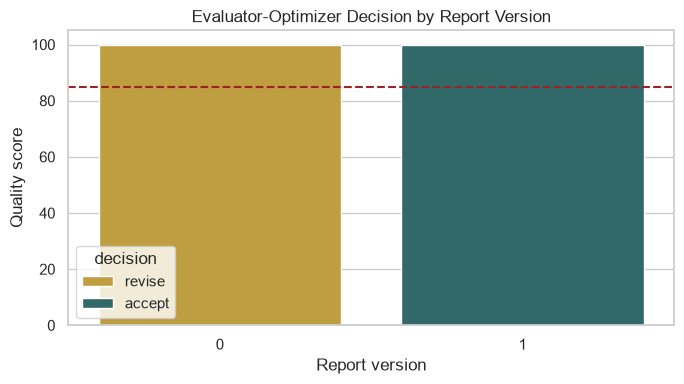

Reflection validation passed: evaluator feedback produced a revised, accepted report.


In [12]:
evaluation_frame = pd.DataFrame(
    [
        {
            "version": index,
            "decision": result.decision,
            "total_score": result.total_score,
            "citation_coverage": result.citation_coverage,
            "numeric_consistency": result.numeric_consistency,
            "groundedness": result.groundedness,
            "question_coverage": result.question_coverage,
            "feedback": "; ".join(result.feedback) or "None",
        }
        for index, result in enumerate(warm_state["evaluations"])
    ]
)
display(evaluation_frame)

fig, axis = plt.subplots(figsize=(7, 4))
sns.barplot(data=evaluation_frame, x="version", y="total_score", hue="decision", dodge=False, ax=axis, palette={"revise": "#d4a72c", "accept": "#287271"})
axis.axhline(85, color="#9b2226", linestyle="--", label="Acceptance threshold")
axis.set_ylim(0, 105)
axis.set_title("Evaluator-Optimizer Decision by Report Version")
axis.set_xlabel("Report version")
axis.set_ylabel("Quality score")
plt.tight_layout()
plt.show()

assert evaluation_frame.iloc[0]["decision"] == "revise"
assert evaluation_frame.iloc[-1]["decision"] == "accept"
print("Reflection validation passed: evaluator feedback produced a revised, accepted report.")

## 10. Learning Across Runs

Durable memory is written only after acceptance. It stores validated company/metric XBRL mappings and compact evaluator lessons, never a mutable conclusion such as “Company X is best.”

The experiment holds the query and frozen data constant. Therefore, any changed planning behavior comes from validated memory rather than new market information.

,run,memory_records_used,fallback_lookups,revisions,quality_score,accepted
0,cold,0,3,1,100.0,True
1,warm,36,0,1,100.0,True


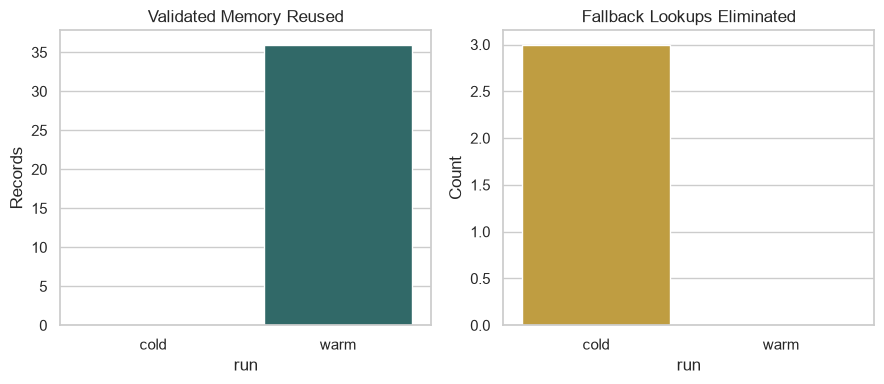

Learning validation passed: memory changed tool behavior without reducing report quality.


In [13]:
display(run_comparison)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.barplot(data=run_comparison, x="run", y="memory_records_used", ax=axes[0], color="#287271")
axes[0].set_title("Validated Memory Reused")
axes[0].set_ylabel("Records")
sns.barplot(data=run_comparison, x="run", y="fallback_lookups", ax=axes[1], color="#d4a72c")
axes[1].set_title("Fallback Lookups Eliminated")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

cold = run_comparison.set_index("run").loc["cold"]
warm = run_comparison.set_index("run").loc["warm"]
assert cold["memory_records_used"] == 0
assert warm["memory_records_used"] > 0
assert warm["fallback_lookups"] < cold["fallback_lookups"]
assert warm["quality_score"] >= cold["quality_score"]
print("Learning validation passed: memory changed tool behavior without reducing report quality.")

## 11. Final Evidence-Linked Research Brief

The final output intentionally avoids an opaque buy/sell score. It presents source-linked findings, catalysts, risks, cross-source divergences, unknowns, and calibrated confidence. Financial execution, filing emphasis, news tone, and market behavior remain distinct evidence classes.

In [14]:
report = warm_state["report"]
print(report.title)
print(report.executive_summary)
print(f"Confidence: {report.confidence:.0%} | Revision: {report.revision}")
print("\nDivergences")
for item in report.divergences:
    print("-", item)
print("\nUnknowns and limitations")
for item in report.unknowns:
    print("-", item)
print("\n", report.disclaimer)

claim_audit = report_claim_audit(warm_state)
display(
    claim_audit[
        [
            "claim_id",
            "claim",
            "citation_count",
            "citations_valid",
            "numbers_reconciled",
        ]
    ]
)
print(f"Citation validity: {claim_audit['citations_valid'].mean():.1%} across {len(claim_audit)} material claims")
print(f"Numeric reconciliation: {claim_audit['numbers_reconciled'].mean():.1%}")

FAANG+M Narrative-to-Numbers Research Brief
The research desk evaluated 6 ticker(s) for 'Compare FAANG+M and identify the largest gaps between AI narrative, capital commitment, cash-flow support, news sentiment, and market reaction.'. It found 14 positive signals, 13 negative signals, and 5 cross-source divergences as of 2026-09-07. The optimized version explicitly separates reported facts, narrative signals, and descriptive market evidence.
Confidence: 90% | Revision: 1

Divergences
- AAPL has both positive and negative evidence across sources.
- AMZN has both positive and negative evidence across sources.
- META has both positive and negative evidence across sources.
- MSFT has both positive and negative evidence across sources.
- NFLX has both positive and negative evidence across sources.

Unknowns and limitations
- Descriptive association; not causal attribution
- FCF is operating cash flow minus capital expenditures
- Headline and supplied summary only; full article was not inges

,claim_id,claim,citation_count,citations_valid,numbers_reconciled
0,C01,"AAPL FY2025: revenue growth -2.8%, operating margin 29.8%, FCF margin 26.0%, and capex intensity 2.9%.",1,True,True
1,C02,"AMZN FY2025: revenue growth 11.8%, operating margin 6.4%, FCF margin 5.6%, and capex intensity 9.2%.",1,True,True
2,C03,"GOOGL FY2025: revenue growth 8.7%, operating margin 27.4%, FCF margin 22.6%, and capex intensity 10.5%.",1,True,True
3,C04,"META FY2025: revenue growth 15.7%, operating margin 34.7%, FCF margin 32.7%, and capex intensity 20.0%.",1,True,True
4,C05,"MSFT FY2026: revenue growth 15.7%, operating margin 44.6%, FCF margin 30.2%, and capex intensity 18.1%.",1,True,True
5,C06,"NFLX FY2025: revenue growth 6.7%, operating margin 20.6%, FCF margin 20.5%, and capex intensity 1.0%.",1,True,True
6,C07,"AAPL returned 39.8%, with 25.2% annualized volatility, -13.8% maximum drawdown, and 12.1% excess return versus QQQ.",1,True,True
7,C08,"AMZN returned 14.7%, with 34.5% annualized volatility, -21.7% maximum drawdown, and -13.0% excess return versus QQQ.",1,True,True
8,C09,"GOOGL returned 60.7%, with 32.6% annualized volatility, -21.0% maximum drawdown, and 33.0% excess return versus QQQ.",1,True,True
9,C10,"META returned -15.8%, with 38.8% annualized volatility, -32.5% maximum drawdown, and -43.5% excess return versus QQQ.",1,True,True


Citation validity: 100.0% across 52 material claims
Numeric reconciliation: 100.0%


## 12. Limitations, Risk Analysis, Ethics, and Conclusion

- **No causal claim:** Benchmark-adjusted returns describe co-movement around a measured window; other events may drive price changes.
- **Fiscal calendars differ:** Microsoft’s latest complete fiscal year is 2026 while most peers report 2025. Period labels remain visible.
- **XBRL is not perfectly uniform:** Amazon’s productive-assets concept is disclosed explicitly, and its standardized R&D value remains missing.
- **News scope is limited:** The system uses titles and provider-supplied summaries, not full copyrighted articles.
- **Sentiment is not investment quality:** FinBERT tone is one signal and can miss irony, context, or long-horizon implications.
- **Small evaluation sets:** Retrieval and planning benchmarks demonstrate behavior but are not market-wide estimates.
- **Shared-model evaluation risk:** Deterministic citation and numeric checks reduce, but do not eliminate, model self-evaluation bias.
- **No investment recommendation:** The system surfaces tensions and unknowns rather than producing automatic buy/sell decisions.

**Conclusion:** The system successfully separates primary-source numbers, management narrative, independent news tone, and descriptive market behavior. Its strongest contribution is not a stock ranking; it is a traceable process for finding where those evidence classes agree, diverge, or remain non-comparable.

The most valuable next improvements are human double-labeling of a larger held-out set, section-aware filing parsing, cross-encoder reranking, and an independent evaluator model.

## 13. References and AI-Assistance Disclosure

**Data and frameworks**

- U.S. Securities and Exchange Commission, EDGAR APIs and filing archives: <https://www.sec.gov/search-filings/edgar-application-programming-interfaces>
- yfinance documentation and usage disclaimer: <https://ranaroussi.github.io/yfinance/>
- LangGraph orchestration and persistence: <https://docs.langchain.com/oss/python/langgraph/overview>
- ProsusAI FinBERT: <https://huggingface.co/ProsusAI/finbert>
- Sentence Transformers all-MiniLM-L6-v2: <https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2>
- Qwen2.5-1.5B-Instruct: <https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct>

**GitHub repository:** The team must place its public or instructor-accessible repository URL here before submission; no Git remote existed in the provided workspace during implementation.

**AI assistance:** GitHub Copilot helped research architecture, draft selected code/documentation, construct validation checks, and debug execution. The student team remains responsible for reviewing, modifying, executing, and understanding the work. Financial calculations are reconciled to cited source data, and AI output is not treated as a financial source. The repository’s `AI_USE_DISCLOSURE.md` must list every tool actually used and each member’s human review before submission.

In [15]:
checks = {
    "six_companies": set(latest["ticker"]) == {company.ticker for company in COMPANIES},
    "no_duplicate_financial_rows": not panel.duplicated(["ticker", "fiscal_year"]).any(),
    "price_data_complete": prices.notna().all().all(),
    "minilm_selected": selected_retriever["method"] == "minilm",
    "retrieval_recall_at_3": selected_retriever["recall_at_3"] >= 0.85,
    "all_news_chain_gates_pass": stage_frame["passed_gate"].all(),
    "routing_specialists_visible": {"filing", "news", "market"}.issubset(set(route_frame["route"])),
    "evaluator_accepts_final": warm_state["evaluations"][-1].decision == "accept",
    "all_claim_evidence_valid": claim_audit["citations_valid"].all() and claim_audit["numbers_reconciled"].all(),
    "memory_changes_behavior": warm["fallback_lookups"] < cold["fallback_lookups"],
    "bounded_revision_count": warm_state["revision_count"] <= SETTINGS.max_revisions,
    "qwen_plan_schema_valid": qwen_cases["schema_valid"].mean() >= 0.90,
}
check_frame = pd.DataFrame({"check": checks.keys(), "passed": checks.values()})
display(check_frame)
assert all(checks.values()), check_frame.loc[~check_frame["passed"], "check"].tolist()
print(f"DELIVERABLE CHECKS PASSED: {sum(checks.values())}/{len(checks)}")

,check,passed
0,six_companies,True
1,no_duplicate_financial_rows,True
2,price_data_complete,True
3,minilm_selected,True
4,retrieval_recall_at_3,True
5,all_news_chain_gates_pass,True
6,routing_specialists_visible,True
7,evaluator_accepts_final,True
8,all_claim_evidence_valid,True
9,memory_changes_behavior,True


DELIVERABLE CHECKS PASSED: 12/12
